# 12 · Currículo generalista → especialista y llevarlo a negocio
**Entornos:** MiniDespacho (perfiles de demanda) y MiniCartas · **Tiempo de ejecución:** ≤ 10 min en CPU · **Criterio de la lección:** en el perfil `urgente`, especialista − generalista con LB > 0; y el agente afinado
en un simulador con error, evaluado en el simulador correcto, rinde peor que el especialista (UB < 0).

## 1. La idea en una frase
Primero se entrena un **generalista** con demanda variada; luego se **afina** una copia en el caso que importa (el especialista). Y cuando entrenas en un simulador, cuidado: si el simulador tiene un error, el agente aprende a explotarlo y su recompensa *reportada* miente.

**En el sistema de Luca:** currículo de generalista a especialista, con la liga y la arena de la lección 11 para decidir qué subir.
**En un problema de negocio:** un despacho entrenado con demanda holgada y pesada se afina para la hora punta ("urgente"); el simulador de la empresa puede medir mal el atraso y la brecha *simulador → realidad* aparece.

## 2. La intuición y la fórmula
- **Especializar aporta solo si el generalista no vio el caso.** Aquí el generalista se entrena en `holgado`, `pesado` y `mediano`, **nunca** en `urgente` (mucha demanda y ventanas de 2 a 4 ticks). El especialista parte *de los pesos del generalista* y se afina en `urgente`.
- **Comparación pareada:** los dos agentes se evalúan en las mismas 1000 semillas; la diferencia por semilla $d_i = R^{esp}_i - R^{gen}_i$ tiene IC de 95 % $\bar d \pm 1{,}96\, s_d/\sqrt n$, y la afirmación "especializar ayuda" pasa si el límite inferior es $> 0$.
- **Brecha simulador → realidad:** un agente afinado en un simulador con error $\tilde R$ maximiza $\tilde R$, no $R$. Si el error premia una conducta mala, $\tilde R$ sube y la $R$ *real* baja.
  Dos errores: `late_at_dispatch` (el atraso se mide al despachar, no al llegar) y el más grueso `no_late_cost` (el simulador no cobra atraso en absoluto).

In [1]:
import os
import copy
import itertools
import time
import numpy as np
import torch
import matplotlib.pyplot as plt
from rlf.core import EVAL_SEED_BASE, VecEnv, seed_everything
from rlf.eval.arena import evaluate_policy, play_games
from rlf.eval.stats import mean_ci, paired_diff_ci, proportion_ci, passes_lower
from rlf.envs.despacho import DespachoEnv
from rlf.envs.cartas import CartasConfig, CartasEnv
from rlf.envs.wrappers import VsOpponent
from rlf.agents.baselines import GreedyDespacho, HeuristicCartas, RandomPolicy
from rlf.agents.policy import ActorCriticPolicy
from rlf.agents.ppo import PPO, PPOConfig
from rlf.nets.pointer import PointerActorCritic
TRAIN_SEED = int(os.environ.get("RLF_TRAIN_SEED", "0"))
seed_everything(TRAIN_SEED)
torch.manual_seed(TRAIN_SEED)
N_EVAL = 1000

## 3. El núcleo: currículo, ajuste fino y evaluación pareada
Tres piezas inline: una fábrica de entornos que **mezcla perfiles**, el **ajuste fino** (copiar la red y seguir entrenando con otra distribución) y la diferencia pareada.

In [2]:
def mixed_env(profiles, bug=None):
    """Fábrica de entornos que reparte los perfiles por turnos: el entorno k usa profiles[k % len(profiles)]."""
    it = itertools.cycle(profiles)
    def make():
        p = next(it)
        return DespachoEnv.from_size("mediano") if p == "mediano" else DespachoEnv.from_profile(p, bug)
    return make

def ppo_config(lr):
    return PPOConfig(gamma=0.97, lam=0.9, lr=lr, epochs=10, minibatches=8, reward_scale=1 / 68, entropy_coef=0.01)

def train(net, make_env, steps, lr, seed):
    ppo = PPO(net, ppo_config(lr), seed=seed)
    ppo.train(VecEnv(make_env, 64, seed=seed), steps)
    return ppo.history

def finetune(generalist, make_env, steps, lr, seed):
    """Especialista = copia del generalista que sigue entrenando en la distribución de interés."""
    net = copy.deepcopy(generalist)
    hist = train(net, make_env, steps, lr, seed)
    return net, hist

_returns = {}
def returns(name, net, profile, bug=None):
    """Retorno por semilla de evaluación (política greedy), con caché para no repetir las mismas evaluaciones."""
    key = (name, profile, bug)
    if key not in _returns:
        if profile == "mediano":
            make = lambda: DespachoEnv.from_size("mediano")
        else:
            make = lambda: DespachoEnv.from_profile(profile, bug)
        _returns[key] = evaluate_policy(make, ActorCriticPolicy(net, greedy=True), N_EVAL)
    return _returns[key]

## 4. Entrenar y graficar
- **Generalista:** `PointerActorCritic`, 200 000 pasos en la mezcla `holgado` + `pesado` + `mediano` (sin `urgente`).
- **Especialista:** copia del generalista, 200 000 pasos en `urgente` (simulador correcto), lr menor.
- **Agente con error:** copia del *mismo* generalista, mismo presupuesto, en `urgente` pero con el simulador que **no cobra atraso** (`no_late_cost`). Como extra, otro con `late_at_dispatch`.

generalista entrenado (66 s)


especialista afinado (136 s)


agente con error no_late_cost afinado (208 s)


agente con error late_at_dispatch afinado (277 s)


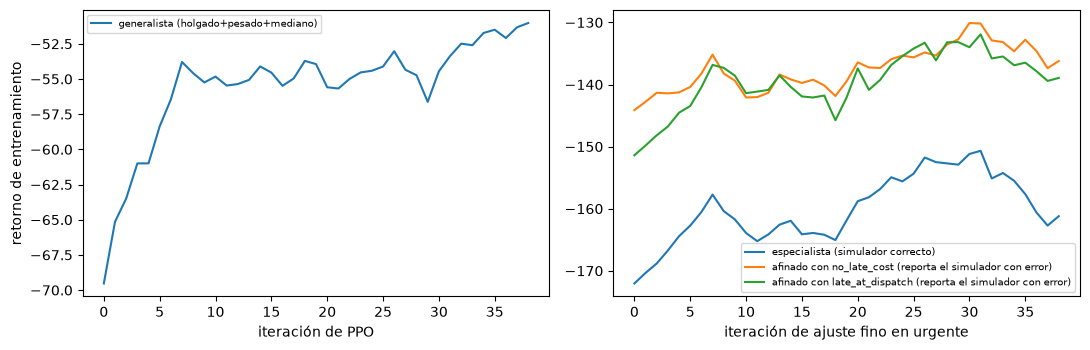

In [3]:
t0 = time.time()
spec = DespachoEnv.from_profile("urgente").spec
generalist = PointerActorCritic(spec)
h_gen = train(generalist, mixed_env(["holgado", "pesado", "mediano"]), 200_000, 1e-3, TRAIN_SEED)
print(f"generalista entrenado ({time.time() - t0:.0f} s)")
specialist, h_esp = finetune(generalist, lambda: DespachoEnv.from_profile("urgente"), 200_000, 5e-4, TRAIN_SEED + 1)
print(f"especialista afinado ({time.time() - t0:.0f} s)")
nolate, h_nolate = finetune(generalist, lambda: DespachoEnv.from_profile("urgente", "no_late_cost"), 200_000, 5e-4, TRAIN_SEED + 1)
print(f"agente con error no_late_cost afinado ({time.time() - t0:.0f} s)")
atdisp, h_atdisp = finetune(generalist, lambda: DespachoEnv.from_profile("urgente", "late_at_dispatch"), 200_000, 5e-4, TRAIN_SEED + 1)
print(f"agente con error late_at_dispatch afinado ({time.time() - t0:.0f} s)")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
sm = lambda h: np.convolve([x["mean_return"] for x in h], np.ones(10) / 10, mode="valid")
ax[0].plot(sm(h_gen), label="generalista (holgado+pesado+mediano)")
ax[0].set_xlabel("iteración de PPO"); ax[0].set_ylabel("retorno de entrenamiento"); ax[0].legend(fontsize=7)
ax[1].plot(sm(h_esp), label="especialista (simulador correcto)")
ax[1].plot(sm(h_nolate), label="afinado con no_late_cost (reporta el simulador con error)")
ax[1].plot(sm(h_atdisp), label="afinado con late_at_dispatch (reporta el simulador con error)")
ax[1].set_xlabel("iteración de ajuste fino en urgente"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

## 5. Experimentos "predice antes de correr"

### Experimento 1 · ¿Cuánto aporta especializar?
**Predice:** el generalista nunca vio `urgente`. ¿Cuánto mejora el especialista en `urgente` frente al generalista y frente a `GreedyDespacho`? (n = 1000 semillas de evaluación, política greedy)

In [4]:
r_rand = evaluate_policy(lambda: DespachoEnv.from_profile("urgente"), RandomPolicy(seed=TRAIN_SEED), N_EVAL)
r_greedy = evaluate_policy(lambda: DespachoEnv.from_profile("urgente"), GreedyDespacho(), N_EVAL)
r_gen, r_esp = returns("gen", generalist, "urgente"), returns("esp", specialist, "urgente")
d_a = paired_diff_ci(r_esp, r_gen)
d_g = paired_diff_ci(r_esp, r_greedy)
print(f"aleatorio {r_rand.mean():.1f} | greedy {r_greedy.mean():.1f} | generalista {r_gen.mean():.1f} | especialista {r_esp.mean():.1f}")
print(f"especialista − generalista: {d_a.mean:+.2f} [{d_a.lo:.2f}, {d_a.hi:.2f}]    especialista − greedy: {d_g.mean:+.2f} [{d_g.lo:.2f}, {d_g.hi:.2f}]")
assert d_a.lo > 0

aleatorio -242.5 | greedy -179.6 | generalista -204.9 | especialista -158.1
especialista − generalista: +46.79 [35.01, 58.57]    especialista − greedy: +21.46 [17.13, 25.79]


<details><summary>Respuesta esperada</summary>

Mejora **mucho**: unas +45 unidades de retorno (semilla 0: generalista ≈ −205, especialista ≈ −158). El generalista sabe despachar, pero nunca vio ventanas tan cortas ni tanta demanda; el ajuste fino le enseña justo eso
en poco tiempo porque ya parte de una política razonable. Ojo: el aporte existe porque el generalista **no incluye** `urgente`; si lo incluyera (o si el generalista ya fuera casi óptimo allí) la diferencia se pierde en el ruido.
</details>

### Experimento 2 · ¿Qué pasa fuera del perfil de afinado?
**Predice:** ¿el especialista, evaluado en `holgado`, `pesado` y `mediano`, queda mejor o peor que el generalista, y dónde gana más?

In [5]:
rows = {}
for prof in ("holgado", "pesado", "mediano"):
    d = paired_diff_ci(returns("esp", specialist, prof), returns("gen", generalist, prof))
    rows[prof] = d
    print(f"{prof:8s} especialista − generalista: {d.mean:+.2f} [{d.lo:.2f}, {d.hi:.2f}]")
gain_elsewhere = float(np.mean([d.mean for d in rows.values()]))
print(f"aporte medio fuera de urgente {gain_elsewhere:+.2f}  vs  en urgente {d_a.mean:+.2f}")
assert d_a.mean > gain_elsewhere

holgado  especialista − generalista: +10.85 [7.62, 14.08]


pesado   especialista − generalista: +23.41 [15.41, 31.42]


mediano  especialista − generalista: +24.68 [16.56, 32.79]
aporte medio fuera de urgente +19.65  vs  en urgente +46.79


<details><summary>Respuesta esperada</summary>

El aporte **fuera** de `urgente` es mucho menor que dentro: semilla 0 ≈ +11 en `holgado`, ≈ +23 en `pesado`, ≈ +25 en `mediano` frente a ≈ +47 en `urgente`; semilla 1 ≈ +2, +4 y +2 frente a ≈ +24 (varios IC incluyen 0).
Cuánto se transfiere depende de la corrida: el generalista de 200 000 pasos no está convergido y el ajuste fino en `urgente` (mucha demanda, ventanas cortas) también ayuda a despachar rápido en otros perfiles.
Lo que sí es estable es el orden: el mayor aporte está en el perfil de afinado. Para saber cuál especialista subir se usa la arena de la lección 11.
</details>

### Experimento 3 · Un simulador con error: ¿qué reporta y qué rinde de verdad?
**Predice:** el agente afinado con `no_late_cost` (el simulador ni cobra atraso). ¿Cuánto *reporta* el simulador con error y cuánto rinde en el simulador correcto, frente al especialista?

In [6]:
d_b = paired_diff_ci(returns("nolate", nolate, "urgente"), r_esp)
rep_b = returns("nolate", nolate, "urgente", "no_late_cost")
print(f"no_late_cost      reporta {rep_b.mean():.1f}   real {returns('nolate', nolate, 'urgente').mean():.1f}   especialista real {r_esp.mean():.1f}")
print(f"  error − especialista (simulador correcto): {d_b.mean:+.2f} [{d_b.lo:.2f}, {d_b.hi:.2f}]")
d_x = paired_diff_ci(returns("atdisp", atdisp, "urgente"), r_esp)
rep_x = returns("atdisp", atdisp, "urgente", "late_at_dispatch")
print(f"late_at_dispatch  reporta {rep_x.mean():.1f}   real {returns('atdisp', atdisp, 'urgente').mean():.1f}   (extra, sin criterio)  error − especialista: {d_x.mean:+.2f} [{d_x.lo:.2f}, {d_x.hi:.2f}]")
assert rep_b.mean() > returns("nolate", nolate, "urgente").mean() + 10

no_late_cost      reporta -137.0   real -174.2   especialista real -158.1
  error − especialista (simulador correcto): -16.05 [-20.33, -11.78]


late_at_dispatch  reporta -144.9   real -180.4   (extra, sin criterio)  error − especialista: -22.30 [-28.31, -16.30]


<details><summary>Respuesta esperada</summary>

Con `no_late_cost` el simulador **reporta ≈ 30 a 37 unidades más** de lo que el agente rinde en realidad (semilla 0: −137 reportado frente a −174 real; semilla 1: −139 frente a −225), y en el simulador correcto queda **peor que el especialista**
(−16 en la semilla 0, −56 en la 1). El agente aprendió a ignorar el atraso porque en su mundo no cuesta nada. `late_at_dispatch`, un error más sutil, también infla lo reportado (≈ +36 y ≈ +30) pero su daño real es menor y varía
(−22 en la semilla 0, −2 en la 1 con IC que incluye 0), por eso el criterio usa el error grueso. Lección de negocio: **valida siempre en el simulador correcto (o en datos reales)**, nunca en el que usaste para entrenar.
</details>

### Experimento 4 · MiniCartas: generalista (mazos aleatorios) vs especialista `aggro`
**Predice:** el generalista juega con un mazo al azar y el especialista parte de él y se afina solo con `aggro`. Contra `HeuristicCartas` (mazo rival al azar), ¿la tasa de victoria con `aggro` sube y llega a superar el 50 %? (Sin criterio: solo se mide.)

In [7]:
def cartas_env(own):
    def configure(env, seat):
        d0, d1 = (own, "random") if seat == 0 else ("random", own)
        env.core.cfg = CartasConfig(d0, d1)
    return lambda: VsOpponent(lambda: CartasEnv(), HeuristicCartas(), configure=configure)

def cartas_ppo(net, own, steps, seed):
    ppo = PPO(net, PPOConfig(gamma=1.0, lam=0.95, lr=1e-3, epochs=6, minibatches=8), seed=seed)
    ppo.train(VecEnv(cartas_env(own), 64, seed=seed), steps)

def win_rate(net, own):
    r = evaluate_policy(cartas_env(own), ActorCriticPolicy(net, greedy=True), N_EVAL)
    return proportion_ci(int((r > 0).sum()), len(r))

t0 = time.time()
torch.manual_seed(TRAIN_SEED)
c_gen = PointerActorCritic(CartasEnv().spec)
cartas_ppo(c_gen, "random", 180_000, TRAIN_SEED)
print(f"generalista de cartas ({time.time() - t0:.0f} s)")
c_esp = copy.deepcopy(c_gen)
cartas_ppo(c_esp, "aggro", 120_000, TRAIN_SEED + 1)
print(f"especialista aggro ({time.time() - t0:.0f} s)")
w_gen, w_esp = win_rate(c_gen, "aggro"), win_rate(c_esp, "aggro")
print(f"con mazo aggro vs heurística: generalista {w_gen.mean:.3f} [{w_gen.lo:.3f}, {w_gen.hi:.3f}]   especialista {w_esp.mean:.3f} [{w_esp.lo:.3f}, {w_esp.hi:.3f}]")
assert w_esp.mean >= w_gen.mean - 0.02     # sin criterio: solo se comprueba que especializar no empeora

generalista de cartas (75 s)


especialista aggro (126 s)


con mazo aggro vs heurística: generalista 0.351 [0.322, 0.381]   especialista 0.399 [0.369, 0.430]


<details><summary>Respuesta esperada</summary>

`aggro` es un mazo débil contra la heurística con mazo al azar: ninguno de los dos llega a 50 % (generalista ≈ 0,34–0,35, especialista ≈ 0,40 en las semillas 0 y 1). El especialista sube unos **+5 a +6 puntos porcentuales**
porque aprende a sacarle jugo a ese mazo concreto, pero sin cambiar el orden general: el ajuste fino mejora *tu* caso, no lo convierte en uno favorable. Este experimento no tiene criterio: se mide, no se afirma.
</details>

## 6. Criterio de la lección

In [8]:
ok_a = passes_lower(d_a, 0.0)
ok_b = d_b.n >= 1000 and d_b.hi < 0.0
print(f"{'afirmación (n = %d semillas, simulador correcto)' % N_EVAL:78s} resultado")
print(f"{'(a) urgente: especialista − generalista = %+.2f [%.2f, %.2f]  (LB > 0)' % (d_a.mean, d_a.lo, d_a.hi):78s} {ok_a}")
print(f"{'(b) afinado con no_late_cost − especialista = %+.2f [%.2f, %.2f]  (UB < 0)' % (d_b.mean, d_b.lo, d_b.hi):78s} {ok_b}")
assert ok_a and ok_b

afirmación (n = 1000 semillas, simulador correcto)                             resultado
(a) urgente: especialista − generalista = +46.79 [35.01, 58.57]  (LB > 0)      True
(b) afinado con no_late_cost − especialista = -16.05 [-20.33, -11.78]  (UB < 0) True


## 7. Resumen y puente
- **Generalista → especialista:** entrenar amplio y afinar en el caso de interés, partiendo de los mismos pesos, mejora el caso de interés **cuando el generalista no lo cubre**; el precio es olvidar parte del resto.
- **Simulador con error:** el agente lo explota, su recompensa reportada sube y la real baja. Evalúa siempre en el simulador correcto o en datos reales.
- **Cierre del curso:** ya tienes todas las piezas del pipeline (interfaz, medición, valor, PPO, pointer, Transformer, self-play, liga y arena, currículo). El `README.md` del repositorio las ordena.